In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv("loanprediction_dataset.csv")
df.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP002305,Female,No,0,Graduate,No,4547,0.0,115.0,360.0,1.0,Semiurban,1
1,LP001715,Male,Yes,3+,Not Graduate,Yes,5703,0.0,130.0,360.0,1.0,Rural,1
2,LP002086,Female,Yes,0,Graduate,No,4333,2451.0,110.0,360.0,1.0,Urban,0
3,LP001136,Male,Yes,0,Not Graduate,Yes,4695,0.0,96.0,NaN,1.0,Urban,1
4,LP002529,Male,Yes,2,Graduate,No,6700,1750.0,230.0,300.0,1.0,Semiurban,1


In [3]:
df.shape

(499, 13)

In [4]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
494     True
495     True
496     True
497     True
498     True
Length: 499, dtype: bool

In [5]:
df.duplicated().sum()

np.int64(8)

In [6]:
df.isnull().sum()

Loan_ID               0
Gender               11
Married               1
Dependents           10
Education             0
Self_Employed        30
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           17
Loan_Amount_Term     13
Credit_History       43
Property_Area         0
Loan_Status           0
dtype: int64

In [7]:
df["Property_Area"].value_counts()

Property_Area
Semiurban      187
Urban          155
Rural          151
 semiurban       1
URBAN            1
rural            1
SemiUrban        1
Urban            1
 Rural           1
Name: count, dtype: int64

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.isnull().sum()

Loan_ID               0
Gender               11
Married               1
Dependents           10
Education             0
Self_Employed        30
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           17
Loan_Amount_Term     13
Credit_History       43
Property_Area         0
Loan_Status           0
dtype: int64

In [10]:
categorical_columns=["Gender","Married","Dependents","Education","Self_Employed","Property_Area"]
for col in categorical_columns:
    print(df[col].value_counts())

Gender
Male       387
Female      87
 male        1
FEMALE       1
Male         1
 female      1
MALE         1
Female       1
Name: count, dtype: int64
Married
Yes      321
No       163
 yes       1
NO         1
Yes        1
no         1
YES        1
 No        1
Name: count, dtype: int64
Dependents
0     275
1      85
2      78
3+     43
Name: count, dtype: int64
Education
Graduate         383
Not Graduate     102
 graduate          1
Graduate           1
not graduate       1
GRADUATE           1
Not graduate       1
 graduate          1
Name: count, dtype: int64
Self_Employed
No      392
Yes      63
 no       1
YES       1
No        1
 yes      1
NO        1
 no       1
Name: count, dtype: int64
Property_Area
Semiurban      183
Urban          154
Rural          148
 semiurban       1
URBAN            1
rural            1
SemiUrban        1
Urban            1
 Rural           1
Name: count, dtype: int64


In [11]:
for col in categorical_columns:
    df[col]=df[col].astype(str).str.strip().str.title()
    print(df[col].value_counts())

Gender
Male      390
Female     90
Nan        11
Name: count, dtype: int64
Married
Yes    324
No     166
Nan      1
Name: count, dtype: int64
Dependents
0      275
1       85
2       78
3+      43
Nan     10
Name: count, dtype: int64
Education
Graduate        387
Not Graduate    104
Name: count, dtype: int64
Self_Employed
No     396
Yes     65
Nan     30
Name: count, dtype: int64
Property_Area
Semiurban    185
Urban        156
Rural        150
Name: count, dtype: int64


In [12]:
df["Dependents"] = df["Dependents"].astype(str).str.strip()
df["Dependents"] = df["Dependents"].replace("3+","3")

In [13]:
df["Dependents"].value_counts()

Dependents
0      275
1       85
2       78
3       43
Nan     10
Name: count, dtype: int64

In [14]:
df.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           17
Loan_Amount_Term     13
Credit_History       43
Property_Area         0
Loan_Status           0
dtype: int64

In [15]:
columns=[ 'Gender', 'Married', 'Dependents', 'Self_Employed']
for col in columns:
    df[col] = df[col].replace("Nan", np.nan)
    df[col] = df[col].replace("nan", np.nan)

In [16]:
df.isnull().sum()

Loan_ID               0
Gender               11
Married               1
Dependents           10
Education             0
Self_Employed        30
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           17
Loan_Amount_Term     13
Credit_History       43
Property_Area         0
Loan_Status           0
dtype: int64

In [17]:
df["Credit_History"].unique()

array([ 1., nan,  0.])

In [18]:
import statistics as st
df["Credit_History"] = df["Credit_History"].fillna(st.mode(df["Credit_History"]))
for col in columns:
    df[col] = df[col].fillna(st.mode(df[col]))

In [19]:
df.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           17
Loan_Amount_Term     13
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [20]:
num_cols=["LoanAmount","Loan_Amount_Term"]
for cols in num_cols:
    df[cols] = df[cols].fillna(df[cols].mean())

In [21]:
##Feature Engineering
df["Total_Income"]=df["ApplicantIncome"]+df["CoapplicantIncome"]


In [22]:
df["LoanAmountperIncome"]=df["LoanAmount"]/df["Total_Income"]

In [23]:
df["Income_Category"]=pd.cut(df["Total_Income"],bins=[0,3000,7000,100000],labels=["Low","Average","High"])

In [24]:
df.isnull().sum()

Loan_ID                0
Gender                 0
Married                0
Dependents             0
Education              0
Self_Employed          0
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount             0
Loan_Amount_Term       0
Credit_History         0
Property_Area          0
Loan_Status            0
Total_Income           0
LoanAmountperIncome    0
Income_Category        0
dtype: int64

In [25]:
print("\nDataset after feature engineering:")
print(df[["ApplicantIncome", "CoapplicantIncome", "Total_Income",
          "LoanAmount", "LoanAmountperIncome", "Income_Category"]].head())



Dataset after feature engineering:
   ApplicantIncome  CoapplicantIncome  Total_Income  LoanAmount  \
0             4547                0.0        4547.0       115.0   
1             5703                0.0        5703.0       130.0   
2             4333             2451.0        6784.0       110.0   
3             4695                0.0        4695.0        96.0   
4             6700             1750.0        8450.0       230.0   

   LoanAmountperIncome Income_Category  
0             0.025291         Average  
1             0.022795         Average  
2             0.016215         Average  
3             0.020447         Average  
4             0.027219            High  


In [26]:
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income,LoanAmountperIncome,Income_Category
0,LP002305,Female,No,0,Graduate,No,4547,0.0,115.0,360.000000,1.0,Semiurban,1,4547.0,0.025291,Average
1,LP001715,Male,Yes,3,Not Graduate,Yes,5703,0.0,130.0,360.000000,1.0,Rural,1,5703.0,0.022795,Average
2,LP002086,Female,Yes,0,Graduate,No,4333,2451.0,110.0,360.000000,1.0,Urban,0,6784.0,0.016215,Average
3,LP001136,Male,Yes,0,Not Graduate,Yes,4695,0.0,96.0,341.297071,1.0,Urban,1,4695.0,0.020447,Average
4,LP002529,Male,Yes,2,Graduate,No,6700,1750.0,230.0,300.000000,1.0,Semiurban,1,8450.0,0.027219,High
5,LP001603,Male,Yes,0,Graduate,No,4344,736.0,87.0,360.000000,1.0,Semiurban,0,5080.0,0.017126,Average
6,LP001273,Male,Yes,0,Graduate,No,6000,2250.0,265.0,360.000000,1.0,Semiurban,0,8250.0,0.032121,High
7,LP002706,Male,Yes,1,Not Graduate,No,5285,1430.0,161.0,360.000000,0.0,Semiurban,1,6715.0,0.023976,Average
8,LP001859,Male,Yes,0,Graduate,No,14683,2100.0,304.0,360.000000,1.0,Rural,0,16783.0,0.018114,High
9,LP001228,Male,No,0,Not Graduate,No,3200,2254.0,126.0,180.000000,0.0,Urban,0,5454.0,0.023102,Average


In [27]:
df.shape

(491, 16)

In [28]:
df.isnull().sum()

Loan_ID                0
Gender                 0
Married                0
Dependents             0
Education              0
Self_Employed          0
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount             0
Loan_Amount_Term       0
Credit_History         0
Property_Area          0
Loan_Status            0
Total_Income           0
LoanAmountperIncome    0
Income_Category        0
dtype: int64

In [29]:
for col in categorical_columns:
    print(df[col])

0      Female
1        Male
2      Female
3        Male
4        Male
        ...  
486      Male
487    Female
488      Male
489      Male
490      Male
Name: Gender, Length: 491, dtype: object
0       No
1      Yes
2      Yes
3      Yes
4      Yes
      ... 
486    Yes
487     No
488    Yes
489     No
490    Yes
Name: Married, Length: 491, dtype: object
0      0
1      3
2      0
3      0
4      2
      ..
486    1
487    1
488    1
489    0
490    0
Name: Dependents, Length: 491, dtype: object
0          Graduate
1      Not Graduate
2          Graduate
3      Not Graduate
4          Graduate
           ...     
486        Graduate
487        Graduate
488        Graduate
489        Graduate
490        Graduate
Name: Education, Length: 491, dtype: object
0       No
1      Yes
2       No
3      Yes
4       No
      ... 
486    Yes
487     No
488     No
489     No
490     No
Name: Self_Employed, Length: 491, dtype: object
0      Semiurban
1          Rural
2          Urban
3          Urb

In [30]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
enc=["Gender","Married","Education","Self_Employed","Property_Area","Income_Category"]
for col in enc:
    df[col]=le.fit_transform(df[col])
    print(df[col].value_counts())

Gender
1    401
0     90
Name: count, dtype: int64
Married
1    325
0    166
Name: count, dtype: int64
Education
0    387
1    104
Name: count, dtype: int64
Self_Employed
0    426
1     65
Name: count, dtype: int64
Property_Area
1    185
2    156
0    150
Name: count, dtype: int64
Income_Category
0    323
1    133
2     35
Name: count, dtype: int64


In [31]:
X=df.drop(columns=["Loan_Status","Loan_ID"])
y=df["Loan_Status"]
X.shape
X.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Total_Income,LoanAmountperIncome,Income_Category
0,0,0,0,0,0,4547,0.0,115.0,360.000000,1.0,1,4547.0,0.025291,0
1,1,1,3,1,1,5703,0.0,130.0,360.000000,1.0,0,5703.0,0.022795,0
2,0,1,0,0,0,4333,2451.0,110.0,360.000000,1.0,2,6784.0,0.016215,0
3,1,1,0,1,1,4695,0.0,96.0,341.297071,1.0,2,4695.0,0.020447,0
4,1,1,2,0,0,6700,1750.0,230.0,300.000000,1.0,1,8450.0,0.027219,1


In [32]:
y.shape

(491,)

In [33]:
X.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Total_Income',
       'LoanAmountperIncome', 'Income_Category'],
      dtype='object')

In [34]:
X['Gender'].value_counts()

Gender
1    401
0     90
Name: count, dtype: int64

In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)
X_train.shape

(392, 14)

In [36]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()


In [37]:
numeric_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Total_Income",
    "LoanAmountperIncome"
]


In [38]:
X_train[numeric_columns] = sc.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = sc.transform(X_test[numeric_columns])


In [39]:
for cols in categorical_columns:
    print(df[cols].value_counts())

Gender
1    401
0     90
Name: count, dtype: int64
Married
1    325
0    166
Name: count, dtype: int64
Dependents
0    285
1     85
2     78
3     43
Name: count, dtype: int64
Education
0    387
1    104
Name: count, dtype: int64
Self_Employed
0    426
1     65
Name: count, dtype: int64
Property_Area
1    185
2    156
0    150
Name: count, dtype: int64


In [40]:
X_train.head(2)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Total_Income,LoanAmountperIncome,Income_Category
140,1,1,0,0,0,-0.517523,0.147490,-0.657496,0.267161,1.0,2,-0.409684,-0.353129,0
433,1,1,3,0,0,-0.130159,-0.135284,-0.402174,0.267161,1.0,2,-0.185132,-0.537816,0


In [41]:
print(X_train.isnull().sum())

Gender                 0
Married                0
Dependents             0
Education              0
Self_Employed          0
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount             0
Loan_Amount_Term       0
Credit_History         0
Property_Area          0
Total_Income           0
LoanAmountperIncome    0
Income_Category        0
dtype: int64


In [42]:
X_train['Credit_History'].value_counts()

Credit_History
1.0    341
0.0     51
Name: count, dtype: int64

In [43]:
X_test['Credit_History'].value_counts()

Credit_History
1.0    82
0.0    17
Name: count, dtype: int64

In [44]:
y_train.shape

(392,)

In [45]:
#from imblearn.over_sampling import SMOTE
#smote = SMOTE(random_state=42)
#X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
#print("Resampled training set shape:", X_train_resampled.shape, y_train_resampled.shape)

In [46]:
X_train.head(30)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Total_Income,LoanAmountperIncome,Income_Category
140,1,1,0,0,0,-0.517523,0.147490,-0.657496,0.267161,1.0,2,-0.409684,-0.353129,0
433,1,1,3,0,0,-0.130159,-0.135284,-0.402174,0.267161,1.0,2,-0.185132,-0.537816,0
416,0,0,0,0,0,-0.034221,-0.535134,-0.146853,0.267161,1.0,0,-0.286592,0.279642,0
489,1,0,0,0,0,-0.553993,10.288655,-0.634284,0.267161,1.0,2,4.386198,-2.514324,1
25,1,1,0,1,0,0.513312,-0.535134,1.570764,0.267161,1.0,0,0.221165,1.122304,1
461,1,1,0,1,0,-0.461341,0.680411,0.006394,-2.490252,1.0,2,-0.103781,-0.069049,0
137,1,1,3,0,0,0.050545,3.079513,4.065950,0.267161,0.0,1,1.513483,0.634928,1
455,1,1,0,0,0,-0.412386,0.115502,-0.262908,0.267161,1.0,1,-0.327419,0.207317,0
349,0,0,0,0,0,-0.278994,-0.535134,-0.796762,0.267161,0.0,2,-0.513581,-0.275893,0
42,0,0,0,0,0,-0.178128,-0.535134,-0.344147,0.267161,1.0,1,-0.420043,0.453473,0


In [47]:
X_train.shape

(392, 14)

In [48]:
X_train['Credit_History'].shape

(392,)

In [49]:
X_train['Credit_History'].value_counts()

Credit_History
1.0    341
0.0     51
Name: count, dtype: int64

In [50]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [51]:
y_pred=lr.predict(X_test)

In [52]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
ac=accuracy_score(y_test,y_pred)
print(ac)

0.797979797979798


In [53]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[17 17]
 [ 3 62]]


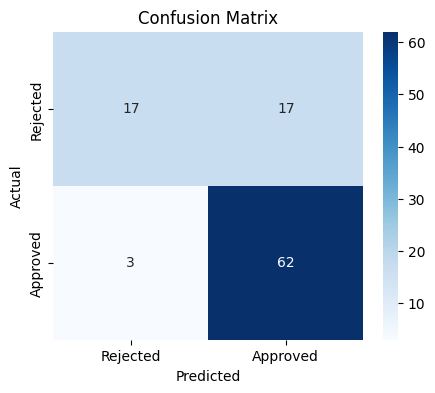

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5,4)) 
sns.heatmap( 
cm, 
annot=True, 
fmt="d", 
cmap="Blues", 
xticklabels=["Rejected", "Approved"], 
yticklabels=["Rejected", "Approved"] 
) 
plt.xlabel("Predicted") 
plt.ylabel("Actual") 
plt.title("Confusion Matrix") 
plt.show() 

In [55]:
from sklearn.tree import DecisionTreeClassifier
dc=DecisionTreeClassifier(criterion = 'entropy',max_depth=5,
    min_samples_split=10,class_weight='balanced', random_state = 0)
dc.fit(X_train,y_train)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [56]:
y_pred_2=dc.predict(X_test)

In [57]:
ac_2=accuracy_score(y_test,y_pred_2)
print(ac_2)

0.7878787878787878


In [58]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred_3 = model.predict(X_test)
ac_3=accuracy_score(y_test,y_pred_3)
print(ac_3)

0.8181818181818182


In [59]:
from sklearn.metrics import precision_score,recall_score,f1_score,classification_report,roc_curve,roc_auc_score
precision = precision_score(y_test, y_pred) 
recall = recall_score(y_test, y_pred) 
f1 = f1_score(y_test, y_pred) 
print("Model Performance")
print("Precision:", precision)
print("Recall   :", recall) 
print("F1 Score :", f1) 

Model Performance
Precision: 0.7848101265822784
Recall   : 0.9538461538461539
F1 Score : 0.8611111111111112


In [60]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.50      0.63        34
           1       0.78      0.95      0.86        65

    accuracy                           0.80        99
   macro avg       0.82      0.73      0.75        99
weighted avg       0.81      0.80      0.78        99



AUC Score: 0.726923076923077


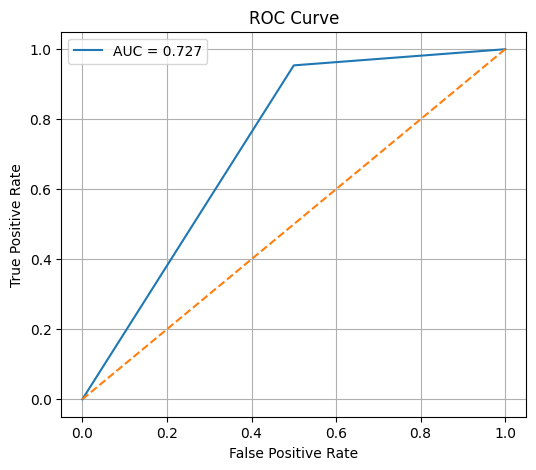

In [61]:
fpr, tpr, threshold = roc_curve(y_test, y_pred) 
auc = roc_auc_score(y_test, y_pred) # Calculate AUC score 
print("AUC Score:", auc) # Plot ROC Curve 
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label="AUC = " + str(round(auc, 3)))
plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate") 
plt.title("ROC Curve") 
plt.legend()
plt.grid(True)
plt.show()

In [62]:
print("Final Results") 
print("----------------------") 
print("Accuracy :", round(ac, 3)) 
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3)) 
print("F1 Score :", round(f1, 3)) 
print("AUC Score:", round(auc, 3)) 

Final Results
----------------------
Accuracy : 0.798
Precision: 0.785
Recall   : 0.954
F1 Score : 0.861
AUC Score: 0.727
